# 03 - Exploratory Data Analysis (Phase 2)
**Goal:** understand how student characteristics relate to `PlacementStatus` *before* any modelling.

**Data used (only):** `data/processed/modeling_dataset.csv` and the split files `train.csv`, `validation.csv`, `test.csv`
produced in notebook 02 (de-duplicated, conflicting-label profiles excluded, stratified 70/15/15, seed 42).
The Phase-1 flagged file and the raw supplied splits are *not* used.

**Ground rules:** no models are trained; no features are engineered or saved; outliers are not removed.
Any binning below is **exploratory, for visualisation only**, lives in temporary variables and is never added to the dataset.
All statements are descriptions of *association in this dataset*, not causal claims.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIGDIR, MET = ROOT / "data" / "processed", ROOT / "results" / "figures" / "eda", ROOT / "results" / "metrics"
FIGDIR.mkdir(parents=True, exist_ok=True); MET.mkdir(parents=True, exist_ok=True)

# ---- consistent visual style: one fixed colour per class, recessive grid, thin marks ----
PLACED_C, NOT_C, NEUTRAL = "#2166ac", "#e08214", "#6b7785"
PAL = {"Placed": PLACED_C, "NotPlaced": NOT_C}
ORDER = ["NotPlaced", "Placed"]
W = 15
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 50)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

SUMMARY = []                       # rows for results/metrics/03_eda_summary.csv
def add(section, item, value, note=""):
    SUMMARY.append({"section": section, "item": item, "value": value, "note": note})

TARGET = "PlacementStatus"
CONT = ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"]   # many-valued scales
COUNT = ["Internships", "Projects", "Workshops/Certifications"]                    # 3-4 level counts
NUM = CONT + COUNT
CATB = ["ExtracurricularActivities", "PlacementTraining"]
FEATURES = NUM + CATB

## 0. Load data and integrity checks

In [2]:
modeling = pd.read_csv(PROC / "modeling_dataset.csv")
splits = {s: pd.read_csv(PROC / f"{s}.csv") for s in ["train", "validation", "test"]}
df = modeling

# --- required checks ---
assert df.isna().sum().sum() == 0 and all(d.isna().sum().sum() == 0 for d in splits.values()), "missing values"
assert set(df[TARGET]) == {"Placed", "NotPlaced"}, "unexpected target classes"
assert not df.duplicated().sum(), "exact duplicate rows exist"
assert not df.duplicated(subset=FEATURES).sum(), "duplicate feature profiles exist"
assert list(df.columns) == sorted(FEATURES, key=list(pd.read_csv(PROC / "train.csv").columns).index) + [TARGET]
profiles = {s: set(map(tuple, d[FEATURES].values)) for s, d in splits.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not (profiles[a] & profiles[b]), f"feature-profile leakage {a}/{b}"
assert sum(map(len, splits.values())) == len(df) and set().union(*profiles.values()) == set(map(tuple, df[FEATURES].values))
print("OK - modelling dataset:", df.shape, "| splits:", {s: len(d) for s, d in splits.items()})
print("Checks passed: no missing values, 2 target classes, no duplicate rows/profiles, zero cross-split profile overlap.")

# numeric target view kept OUTSIDE the dataframe (no new columns are created)
y = (df[TARGET] == "Placed").astype(int)

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def rate_table(by):
    # placement rate per group with n and Wilson 95% CI (descriptive uncertainty)
    t = y.groupby(by, observed=True).agg(n="size", placed="sum")
    t["rate"] = t.placed / t.n
    t["ci_lo"], t["ci_hi"] = wilson(t.placed, t.n)
    return t

OVERALL = y.mean()

def rate_bar(ax, by, title, xlabel=None, rot=0):
    t = rate_table(by)
    x = np.arange(len(t))
    ax.bar(x, t.rate * 100, color=PLACED_C, width=0.62)
    ax.errorbar(x, t.rate * 100, yerr=[(t.rate - t.ci_lo) * 100, (t.ci_hi - t.rate) * 100], fmt="none", ecolor="#1d2733", lw=1.1, capsize=3)
    for xi, (r, hi, n) in enumerate(zip(t.rate, t.ci_hi, t.n)):
        ax.text(xi, hi * 100 + 2, f"{r*100:.1f}%\nn={n:,}", ha="center", va="bottom", fontsize=8.5, color="#1d2733")
    ax.axhline(OVERALL * 100, color=NEUTRAL, ls="--", lw=1)
    ax.text(0.02, 0.97, f"- - overall rate {OVERALL*100:.1f}%", transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=NEUTRAL)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in t.index], rotation=rot, ha="right" if rot else "center")
    ax.set_ylim(0, 118); ax.set_ylabel("Placement rate (%)"); ax.set_xlabel(xlabel or ""); ax.set_title(title)
    ax.grid(axis="x", visible=False)
    return t

def cohens_d(a, b):
    na, nb_ = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb_ - 1) * b.var(ddof=1)) / (na + nb_ - 2))
    return (a.mean() - b.mean()) / sp

OK - modelling dataset: (9912, 11) | splits: {'train': 6938, 'validation': 1487, 'test': 1487}
Checks passed: no missing values, 2 target classes, no duplicate rows/profiles, zero cross-split profile overlap.


## 1. Dataset overview
Predictors fall into three groups: **5 scale-type numeric** variables (CGPA, aptitude, soft skills, SSC, HSC marks - many
distinct values, but bounded and recorded in coarse steps), **3 count-type numeric** variables (3-4 levels each, treated as
ordered categories when plotting) and **2 binary categorical** variables.

In [3]:
overview = pd.DataFrame({
    "Item": ["Rows", "Predictors", "Numeric predictors", "  scale-type (many levels)", "  count-type (<=4 levels)",
             "Categorical predictors (binary)", "Target", "Placed", "NotPlaced"],
    "Value": [f"{len(df):,}", len(FEATURES), len(NUM), ", ".join(CONT), ", ".join(COUNT), ", ".join(CATB), TARGET,
              f"{(y==1).sum():,} ({y.mean()*100:.2f}%)", f"{(y==0).sum():,} ({(1-y.mean())*100:.2f}%)"]})
add("overview", "rows", len(df)); add("overview", "predictors", len(FEATURES))
add("overview", "placed_pct", round(y.mean() * 100, 2)); add("overview", "notplaced_pct", round((1 - y.mean()) * 100, 2))
overview

,Item,Value
0,Rows,"9,912"
1,Predictors,10
2,Numeric predictors,8
3,scale-type (many levels),"CGPA, AptitudeTestScore, SoftSkillsRating, SSC..."
4,count-type (<=4 levels),"Internships, Projects, Workshops/Certifications"
5,Categorical predictors (binary),"ExtracurricularActivities, PlacementTraining"
6,Target,PlacementStatus
7,Placed,"4,119 (41.56%)"
8,NotPlaced,"5,793 (58.44%)"


In [4]:
desc = df[NUM].agg(["mean", "median", "std", "min", "max", "skew"]).T
desc["n_unique"] = df[NUM].nunique()
print("Descriptive statistics (skewness is most informative for the scale-type variables):")
desc.round(3)

Descriptive statistics (skewness is most informative for the scale-type variables):


,mean,median,std,min,max,skew,n_unique
CGPA,7.693,7.7,0.640,6.5,9.1,-0.392,27
AptitudeTestScore,79.359,80.0,8.136,60.0,90.0,-0.347,31
SoftSkillsRating,4.320,4.4,0.411,3.0,4.8,-0.668,19
SSC_Marks,69.080,70.0,10.429,55.0,90.0,0.048,36
HSC_Marks,74.411,73.0,8.901,57.0,88.0,0.013,32
Internships,1.041,1.0,0.663,0.0,2.0,-0.046,3
Projects,2.018,2.0,0.867,0.0,3.0,-0.063,4
Workshops/Certifications,1.005,1.0,0.903,0.0,3.0,0.223,4


In [5]:
print("Categorical predictors:")
pd.DataFrame({c: df[c].value_counts() for c in CATB}).T.assign(**{"Yes %": lambda t: (t["Yes"] / len(df) * 100).round(1)})

Categorical predictors:


,Yes,No,Yes %
ExtracurricularActivities,5768,4144,58.2
PlacementTraining,7230,2682,72.9


## 2. Target distribution

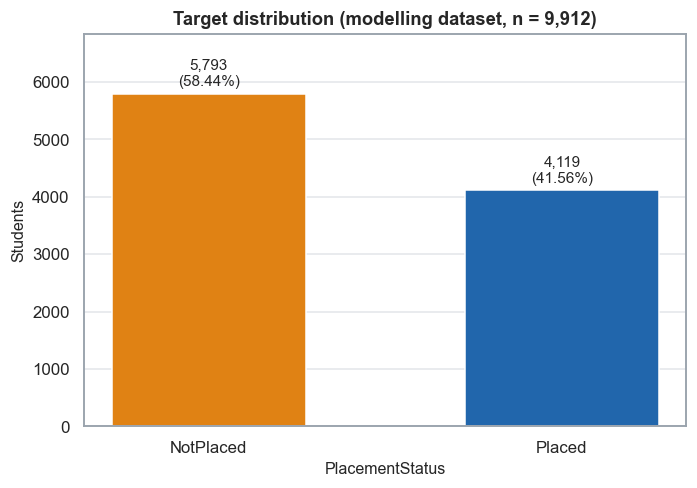

NotPlaced 5,793 (58.44%)  vs  Placed 4,119 (41.56%)  -> ratio 1.41:1


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
vc = df[TARGET].value_counts().reindex(ORDER)
bars = ax.bar(ORDER, vc.values, color=[PAL[c] for c in ORDER], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 80, f"{v:,}\n({v/len(df)*100:.2f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, vc.max() * 1.18); ax.set_ylabel("Students"); ax.set_xlabel("PlacementStatus")
ax.set_title("Target distribution (modelling dataset, n = %s)" % f"{len(df):,}"); ax.grid(axis="x", visible=False)
save(fig, "eda_01_target_distribution")
ratio = vc["NotPlaced"] / vc["Placed"]
print(f"NotPlaced {vc['NotPlaced']:,} ({vc['NotPlaced']/len(df)*100:.2f}%)  vs  Placed {vc['Placed']:,} ({vc['Placed']/len(df)*100:.2f}%)  -> ratio {ratio:.2f}:1")
add("target", "imbalance_ratio_notplaced_to_placed", round(ratio, 3))

**Class balance:** about 58.4% NotPlaced vs 41.6% Placed (roughly 1.4 : 1). This is a moderate imbalance, not a severe one;
accuracy alone would still be a poor headline metric later (always predicting `NotPlaced` already scores ~58%), so
threshold-free and probability-based metrics will be preferred in modelling.

## 3. Numerical feature distributions
Scale-type variables get histograms with a KDE overlay (bin width matched to the recording step so integer/0.1-step gaps do
not create artificial spikes). Count-type variables are shown as bar charts of level frequencies - a KDE or an outlier
rule is not meaningful for 3-4 level counts.

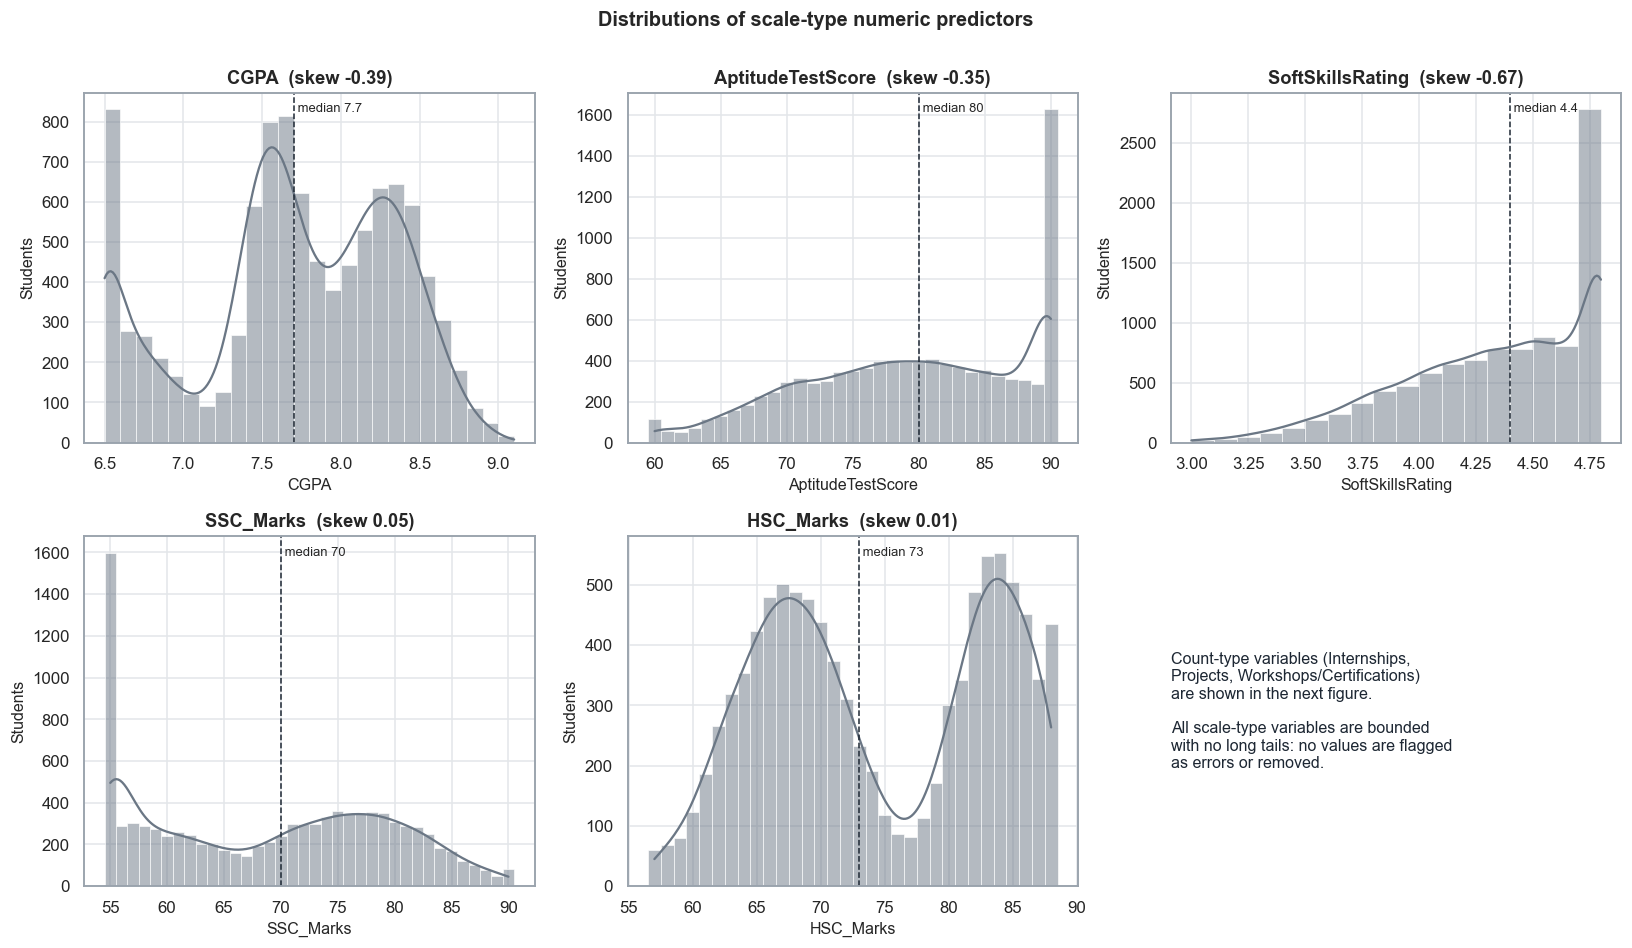

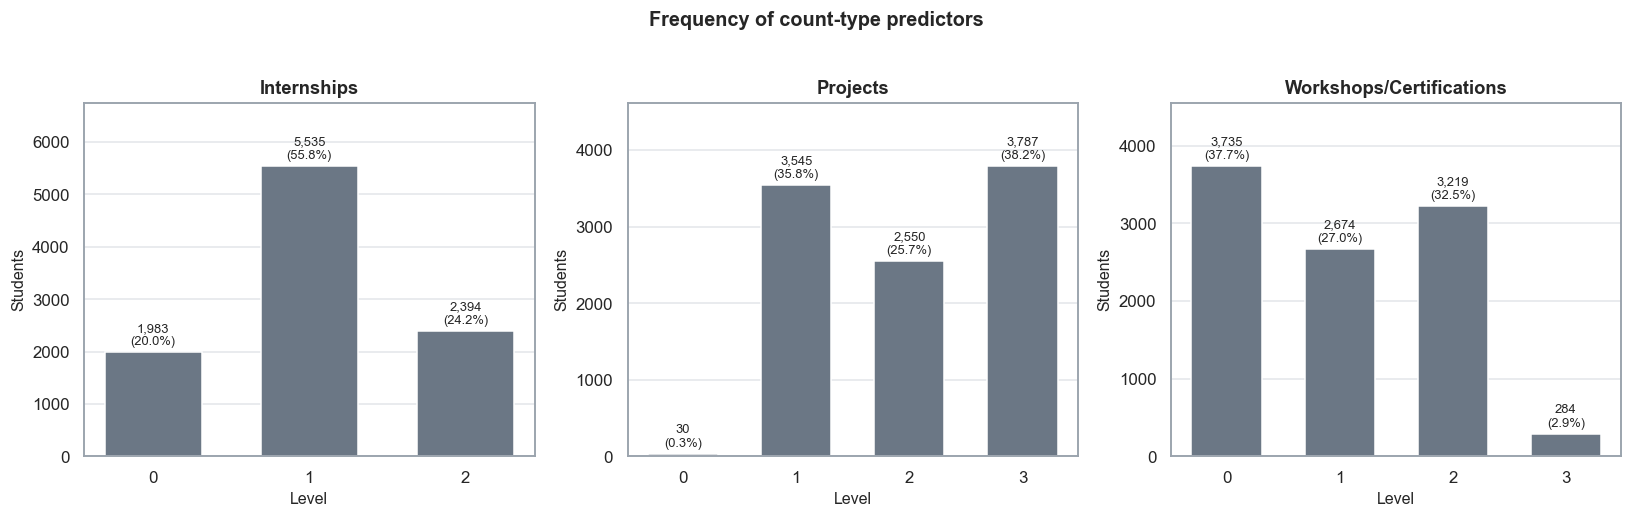

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(W, 8.6))
kw = {"CGPA": dict(binwidth=0.1), "SoftSkillsRating": dict(binwidth=0.1),
      "AptitudeTestScore": dict(discrete=True), "SSC_Marks": dict(discrete=True), "HSC_Marks": dict(discrete=True)}
for ax, c in zip(axes.ravel(), CONT):
    sns.histplot(df[c], kde=True, color=NEUTRAL, edgecolor="white", linewidth=0.4, ax=ax, **kw[c])
    ax.axvline(df[c].median(), color="#1d2733", ls="--", lw=1)
    ax.text(df[c].median(), ax.get_ylim()[1] * 0.97, f" median {df[c].median():g}", fontsize=8.5, va="top")
    ax.set_title(f"{c}  (skew {df[c].skew():.2f})"); ax.set_xlabel(c); ax.set_ylabel("Students")
ax = axes.ravel()[-1]; ax.axis("off")
ax.text(0, 0.5, "Count-type variables (Internships,\nProjects, Workshops/Certifications)\nare shown in the next figure.\n\nAll scale-type variables are bounded\nwith no long tails: no values are flagged\nas errors or removed.", fontsize=10.5, va="center", color="#1d2733")
fig.suptitle("Distributions of scale-type numeric predictors", y=1.0, fontsize=13, fontweight="semibold")
save(fig, "eda_02_scale_distributions")

fig, axes = plt.subplots(1, 3, figsize=(W, 4.6))
for ax, c in zip(axes, COUNT):
    vc_ = df[c].value_counts().sort_index()
    ax.bar(vc_.index.astype(str), vc_.values, color=NEUTRAL, width=0.62)
    for i, v in enumerate(vc_.values):
        ax.text(i, v + vc_.max() * 0.015, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=8.5)
    ax.set_ylim(0, vc_.max() * 1.22); ax.set_title(c); ax.set_xlabel("Level"); ax.set_ylabel("Students"); ax.grid(axis="x", visible=False)
fig.suptitle("Frequency of count-type predictors", y=1.02, fontsize=13, fontweight="semibold")
save(fig, "eda_02b_count_distributions")

In [8]:
dist = df[NUM].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
dist["n_unique"] = df[NUM].nunique()
dist["modal_share_%"] = [df[c].value_counts(normalize=True).iloc[0] * 100 for c in NUM]
dist.round(3)

,count,mean,median,std,min,max,skew,kurt,n_unique,modal_share_%
CGPA,9912.0,7.693,7.7,0.640,6.5,9.1,-0.392,-0.745,27,8.384
AptitudeTestScore,9912.0,79.359,80.0,8.136,60.0,90.0,-0.347,-0.851,31,16.435
SoftSkillsRating,9912.0,4.320,4.4,0.411,3.0,4.8,-0.668,-0.321,19,19.794
SSC_Marks,9912.0,69.080,70.0,10.429,55.0,90.0,0.048,-1.307,36,16.122
HSC_Marks,9912.0,74.411,73.0,8.901,57.0,88.0,0.013,-1.406,32,5.579
Internships,9912.0,1.041,1.0,0.663,0.0,2.0,-0.046,-0.730,3,55.841
Projects,9912.0,2.018,2.0,0.867,0.0,3.0,-0.063,-1.602,4,38.206
Workshops/Certifications,9912.0,1.005,1.0,0.903,0.0,3.0,0.223,-1.264,4,37.682


## 4. Placement vs numerical features
Violin plots (with inner box) for the scale-type variables; effect size is summarised as Cohen's *d* (Placed minus NotPlaced,
in pooled-SD units). *d* here is a **descriptive** effect size; formal testing is deferred to Phase 3.

In [9]:
rows = []
for c in NUM:
    a, b = df.loc[y == 1, c], df.loc[y == 0, c]
    rows.append({"feature": c, "mean_placed": a.mean(), "mean_notplaced": b.mean(), "median_placed": a.median(),
                 "median_notplaced": b.median(), "sd_placed": a.std(), "sd_notplaced": b.std(), "cohens_d": cohens_d(a, b)})
    add("numeric_vs_target", f"{c}: cohens_d", round(cohens_d(a, b), 3), "Placed minus NotPlaced, pooled SD")
    add("numeric_vs_target", f"{c}: mean_placed", round(a.mean(), 3)); add("numeric_vs_target", f"{c}: mean_notplaced", round(b.mean(), 3))
cmp = pd.DataFrame(rows).set_index("feature")
cmp.round(3)

,mean_placed,mean_notplaced,median_placed,median_notplaced,sd_placed,sd_notplaced,cohens_d
feature,,,,,,,
CGPA,8.011,7.467,8.2,7.5,0.550,0.602,0.936
AptitudeTestScore,84.351,75.810,86.0,76.0,6.179,7.471,1.227
SoftSkillsRating,4.526,4.174,4.6,4.2,0.319,0.407,0.945
SSC_Marks,74.848,64.979,76.0,62.0,8.798,9.519,1.070
HSC_Marks,79.702,70.648,83.0,69.0,7.658,7.733,1.176
Internships,1.240,0.900,1.0,1.0,0.710,0.588,0.529
Projects,2.502,1.674,3.0,1.0,0.753,0.773,1.083
Workshops/Certifications,1.388,0.733,2.0,1.0,0.911,0.793,0.776


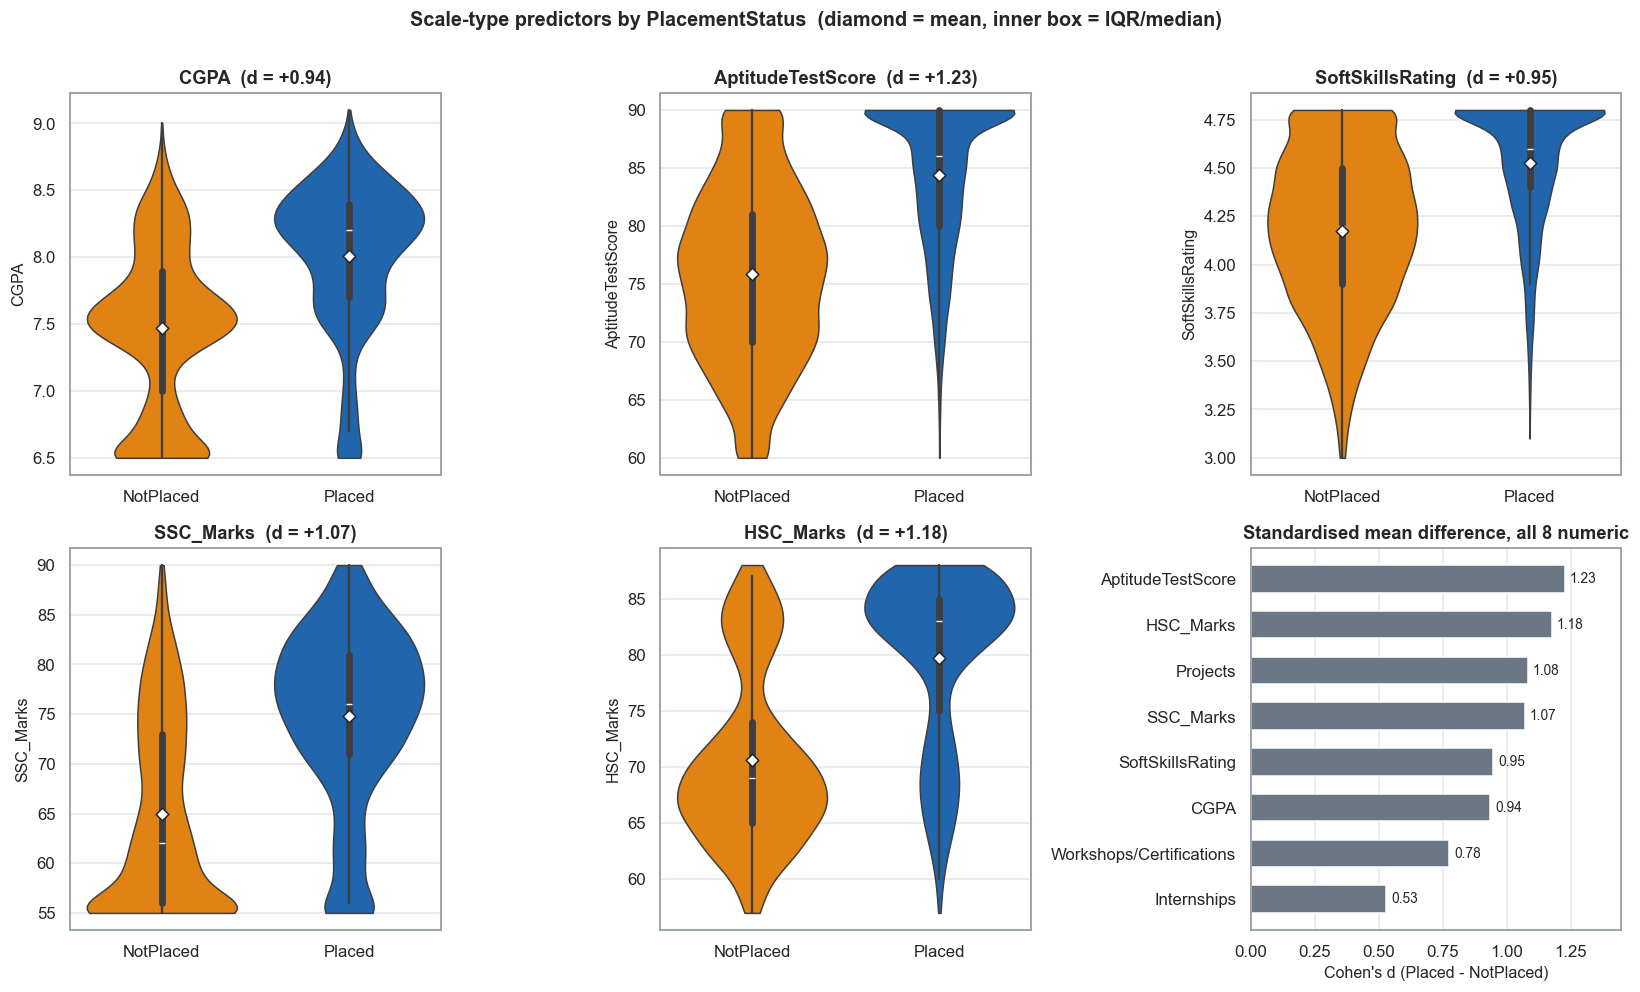

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(W, 9))
for ax, c in zip(axes.ravel(), CONT):
    sns.violinplot(data=df, x=TARGET, y=c, order=ORDER, hue=TARGET, hue_order=ORDER, palette=PAL, inner="box", cut=0,
                   linewidth=1, saturation=1, legend=False, ax=ax)
    for i, g in enumerate(ORDER):
        m = df.loc[df[TARGET] == g, c].mean()
        ax.scatter(i, m, marker="D", s=34, color="white", edgecolor="#1d2733", zorder=5)
    ax.set_title(f"{c}  (d = {cmp.loc[c, 'cohens_d']:+.2f})"); ax.set_xlabel(""); ax.set_ylabel(c)
ax = axes.ravel()[-1]
cm = cmp.cohens_d.sort_values()
ax.barh(cm.index, cm.values, color=NEUTRAL, height=0.6)
for i, v in enumerate(cm.values): ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, cm.max() * 1.18); ax.set_xlabel("Cohen's d (Placed - NotPlaced)"); ax.set_title("Standardised mean difference, all 8 numeric"); ax.grid(axis="y", visible=False)
fig.suptitle("Scale-type predictors by PlacementStatus  (diamond = mean, inner box = IQR/median)", y=1.0, fontsize=13, fontweight="semibold")
save(fig, "eda_03_scale_vs_placement")

### Count-type predictors: placement rate per level
Whiskers are Wilson 95% intervals - they show how much sampling noise is attached to each rate (very wide when *n* is small).
No monotonic pattern is assumed.

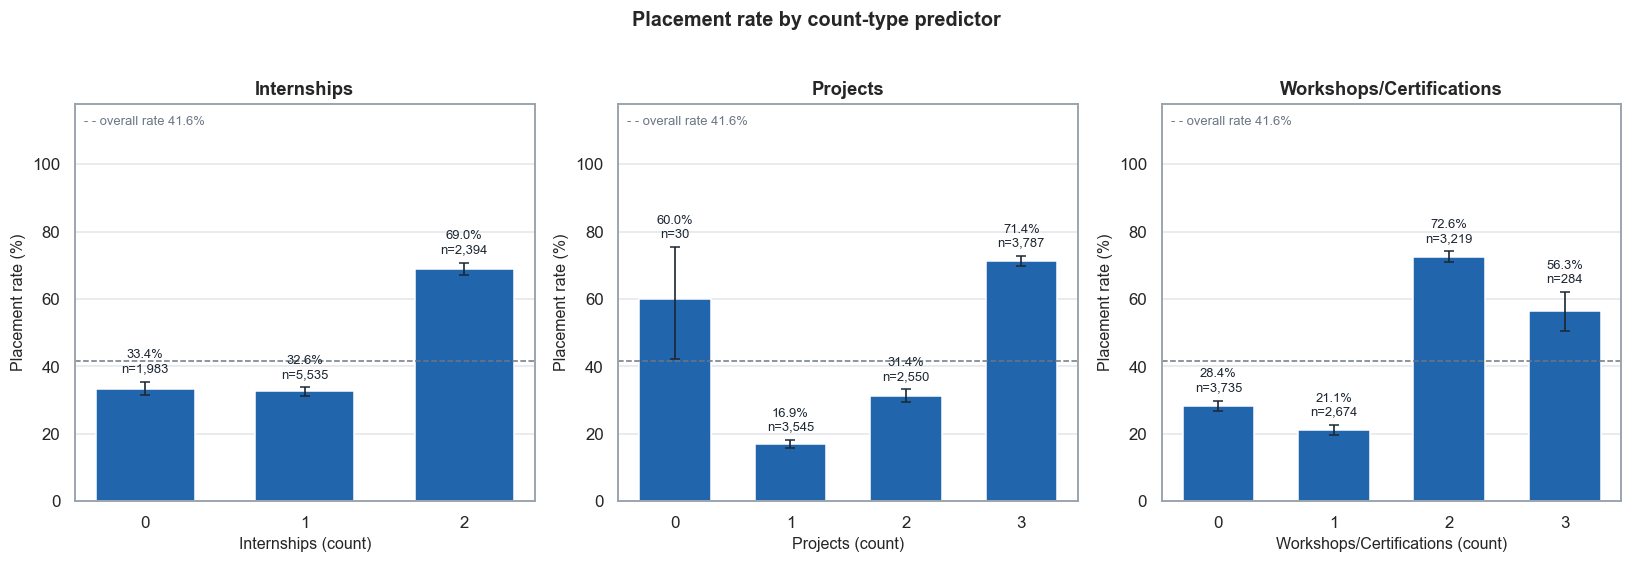

--- Internships ---
                n  placed  rate  ci_lo  ci_hi
Internships                                  
0            1983     663  33.4   31.4   35.5
1            5535    1805  32.6   31.4   33.9
2            2394    1651  69.0   67.1   70.8 

--- Projects ---
             n  placed  rate  ci_lo  ci_hi
Projects                                  
0           30      18  60.0   42.3   75.4
1         3545     598  16.9   15.7   18.1
2         2550     800  31.4   29.6   33.2
3         3787    2703  71.4   69.9   72.8 

--- Workshops/Certifications ---
                             n  placed  rate  ci_lo  ci_hi
Workshops/Certifications                                  
0                         3735    1059  28.4   26.9   29.8
1                         2674     563  21.1   19.6   22.6
2                         3219    2337  72.6   71.0   74.1
3                          284     160  56.3   50.5   62.0 



In [11]:
fig, axes = plt.subplots(1, 3, figsize=(W, 5))
count_tabs = {}
for ax, c in zip(axes, COUNT):
    count_tabs[c] = rate_bar(ax, df[c], c, xlabel=f"{c} (count)")
fig.suptitle("Placement rate by count-type predictor", y=1.02, fontsize=13, fontweight="semibold")
save(fig, "eda_04_count_vs_placement")
for c, t in count_tabs.items():
    print(f"--- {c} ---"); print((t.assign(rate=t.rate * 100, ci_lo=t.ci_lo * 100, ci_hi=t.ci_hi * 100)).round(1).to_string(), "\n")
    for lvl, r in t.iterrows():
        add("count_rate", f"{c}={lvl}: placement_rate_%", round(r.rate * 100, 2), f"n={int(r.n)}")

### Investigating the non-monotonic patterns
Placement rate does **not** rise steadily with Internships or Workshops (e.g. Workshops = 1 is *below* Workshops = 0, and 3 is
below 2). Three descriptive checks look for an explanation:
1. Do students at different levels differ in their *other* characteristics (a composition effect)?
2. Do the patterns hold inside combinations of count variables?
3. Does the Workshops pattern persist within bands of aptitude (an exploratory split, used only here)?

In [12]:
prof = df.groupby("Workshops/Certifications")[["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks", "Internships", "Projects"]].mean()
prof["Extracurricular=Yes %"] = df.groupby("Workshops/Certifications")["ExtracurricularActivities"].apply(lambda s: (s == "Yes").mean() * 100)
prof["PlacementTraining=Yes %"] = df.groupby("Workshops/Certifications")["PlacementTraining"].apply(lambda s: (s == "Yes").mean() * 100)
prof["n"] = df["Workshops/Certifications"].value_counts().sort_index()
prof["placement_rate_%"] = count_tabs["Workshops/Certifications"].rate * 100
print("Average profile of students at each Workshops/Certifications level:")
display(prof.round(2))
prof2 = df.groupby("Projects")[["CGPA", "AptitudeTestScore", "SSC_Marks", "HSC_Marks"]].mean().round(2)
prof2["n"] = df["Projects"].value_counts().sort_index(); prof2["placement_rate_%"] = (count_tabs["Projects"].rate * 100).round(1)
print("Average profile of students at each Projects level:"); display(prof2)

Average profile of students at each Workshops/Certifications level:


,CGPA,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks,Internships,Projects,Extracurricular=Yes %,PlacementTraining=Yes %,n,placement_rate_%
Workshops/Certifications,,,,,,,,,,,
0,7.51,77.09,4.21,66.07,71.47,0.89,1.76,43.32,66.69,3735,28.35
1,7.48,75.65,4.19,65.03,70.78,0.89,1.69,41.25,65.45,2674,21.05
2,8.05,84.81,4.55,75.61,80.46,1.33,2.56,87.45,85.37,3219,72.60
3,7.97,82.38,4.43,72.79,78.67,1.23,2.33,81.69,84.86,284,56.34


Average profile of students at each Projects level:


,CGPA,AptitudeTestScore,SSC_Marks,HSC_Marks,n,placement_rate_%
Projects,,,,,,
0,7.86,79.13,69.47,74.83,30,60.0
1,7.40,74.72,63.53,69.30,3545,16.9
2,7.58,77.62,67.09,72.69,2550,31.4
3,8.04,84.88,75.61,80.35,3787,71.4


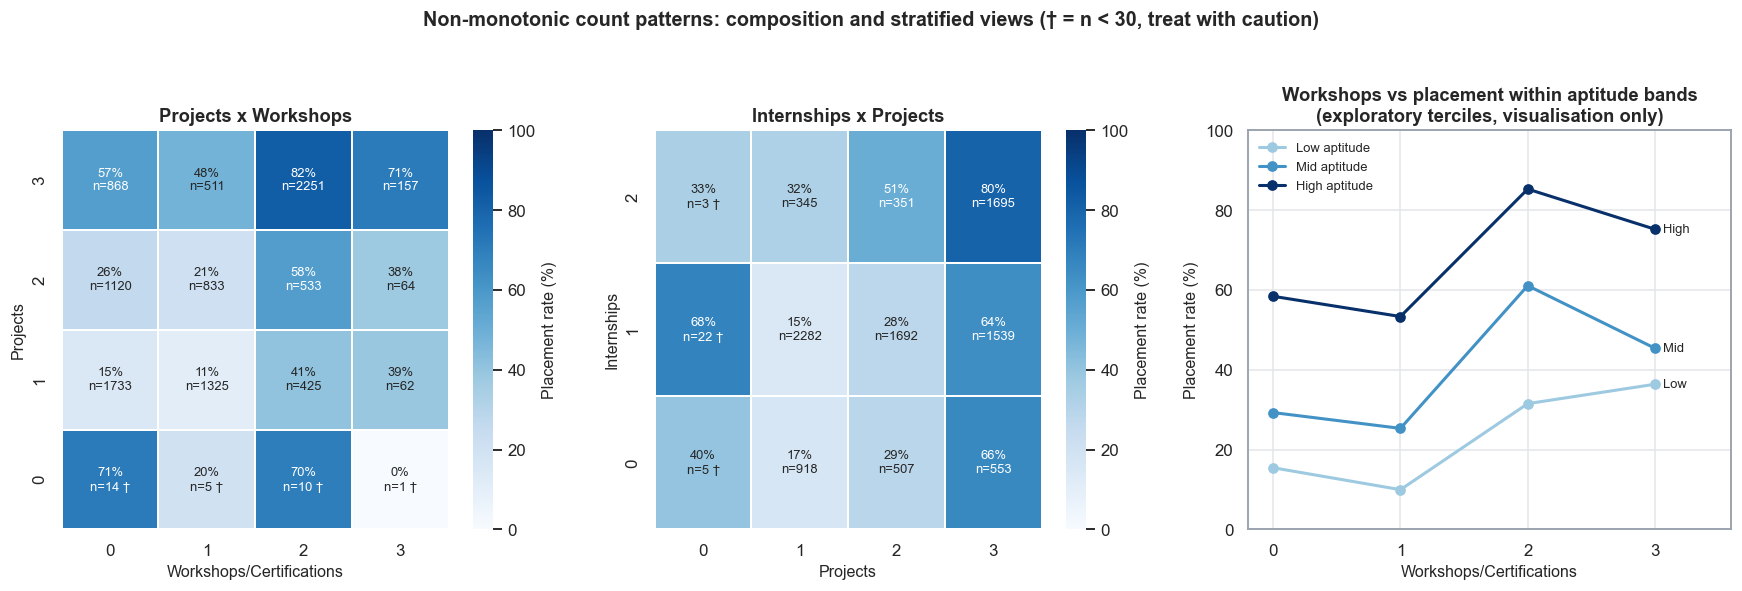

Placement rate (%) of Workshops level within aptitude tercile:


AptitudeTestScore,Low aptitude,Mid aptitude,High aptitude
Workshops/Certifications,,,
0,15.4,29.3,58.4
1,9.9,25.3,53.3
2,31.5,61.1,85.3
3,36.4,45.4,75.2


n per cell:


AptitudeTestScore,Low aptitude,Mid aptitude,High aptitude
Workshops/Certifications,,,
0,1724,1309,702
1,1450,834,390
2,381,840,1998
3,55,108,121


In [13]:
def rate_heat(ax, rows, cols, title):
    r = y.groupby([df[rows], df[cols]]).mean().unstack(); n = y.groupby([df[rows], df[cols]]).size().unstack()
    ann = r.copy().astype(object)
    for i in r.index:
        for j in r.columns:
            nn = n.loc[i, j]; ann.loc[i, j] = "" if pd.isna(nn) else f"{r.loc[i, j]*100:.0f}%\nn={int(nn)}" + (" †" if nn < 30 else "")
    sns.heatmap(r * 100, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "Placement rate (%)"}, linewidths=1,
                linecolor="white", annot_kws={"fontsize": 8.5}, ax=ax)
    ax.set_title(title); ax.set_xlabel(cols); ax.set_ylabel(rows); ax.invert_yaxis()
    return r, n

fig, axes = plt.subplots(1, 3, figsize=(W + 1, 5.2))
rate_heat(axes[0], "Projects", "Workshops/Certifications", "Projects x Workshops")
rate_heat(axes[1], "Internships", "Projects", "Internships x Projects")
# exploratory aptitude bands (visualisation only; temporary variable, never stored in df)
apt_band = pd.qcut(df["AptitudeTestScore"], 3, labels=["Low aptitude", "Mid aptitude", "High aptitude"], duplicates="drop")
assert apt_band.nunique() == 3
t = y.groupby([df["Workshops/Certifications"], apt_band], observed=True).agg(["mean", "size"]).reset_index()
shade = {"Low aptitude": "#9ecae1", "Mid aptitude": "#4292c6", "High aptitude": "#08306b"}
for band in shade:
    s = t[t.AptitudeTestScore == band] if "AptitudeTestScore" in t else None
    axes[2].plot(s["Workshops/Certifications"], s["mean"] * 100, marker="o", color=shade[band], lw=2, label=band)
    axes[2].text(s["Workshops/Certifications"].iloc[-1] + 0.06, s["mean"].iloc[-1] * 100, band.split()[0], fontsize=8.5, va="center")
axes[2].set_xticks([0, 1, 2, 3]); axes[2].set_xlim(-0.2, 3.6); axes[2].set_ylim(0, 100)
axes[2].set_xlabel("Workshops/Certifications"); axes[2].set_ylabel("Placement rate (%)")
axes[2].set_title("Workshops vs placement within aptitude bands\n(exploratory terciles, visualisation only)"); axes[2].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("Non-monotonic count patterns: composition and stratified views († = n < 30, treat with caution)", y=1.03, fontsize=13, fontweight="semibold")
save(fig, "eda_04b_nonmonotonic_investigation")
strat = t.pivot(index="Workshops/Certifications", columns="AptitudeTestScore", values="mean").mul(100).round(1)
strat_n = t.pivot(index="Workshops/Certifications", columns="AptitudeTestScore", values="size")
print("Placement rate (%) of Workshops level within aptitude tercile:"); display(strat); print("n per cell:"); display(strat_n)
for lvl in strat.index:
    for band in strat.columns:
        add("workshops_within_aptitude_band", f"workshops={lvl}, {band}: rate_%", strat.loc[lvl, band], f"n={int(strat_n.loc[lvl, band])}")

**Reading these three views (descriptive only).** The students with 2 Workshops/Certifications also have noticeably higher
average CGPA, aptitude and project counts and are far more likely to report extracurriculars and placement training than
students with 0-1 workshops (first table). So the Workshops level is entangled with an overall "stronger profile" pattern,
and its raw placement rate partly reflects who sits at each level. The within-aptitude view shows whether the dip at level 1
survives once aptitude is held roughly constant. Cells marked † (e.g. Projects = 0, n = 30) rest on very few students and should
not be interpreted individually. Whether these relationships hold up statistically is a Phase 3 question.

## 5. Categorical features

--- ExtracurricularActivities ---
                              n  placed  rate  ci_lo  ci_hi  share_pct
ExtracurricularActivities                                             
No                         4144     567  13.7   12.7   14.8       41.8
Yes                        5768    3552  61.6   60.3   62.8       58.2 

--- PlacementTraining ---
                      n  placed  rate  ci_lo  ci_hi  share_pct
PlacementTraining                                             
No                 2682     418  15.6   14.3   17.0       27.1
Yes                7230    3701  51.2   50.0   52.3       72.9 



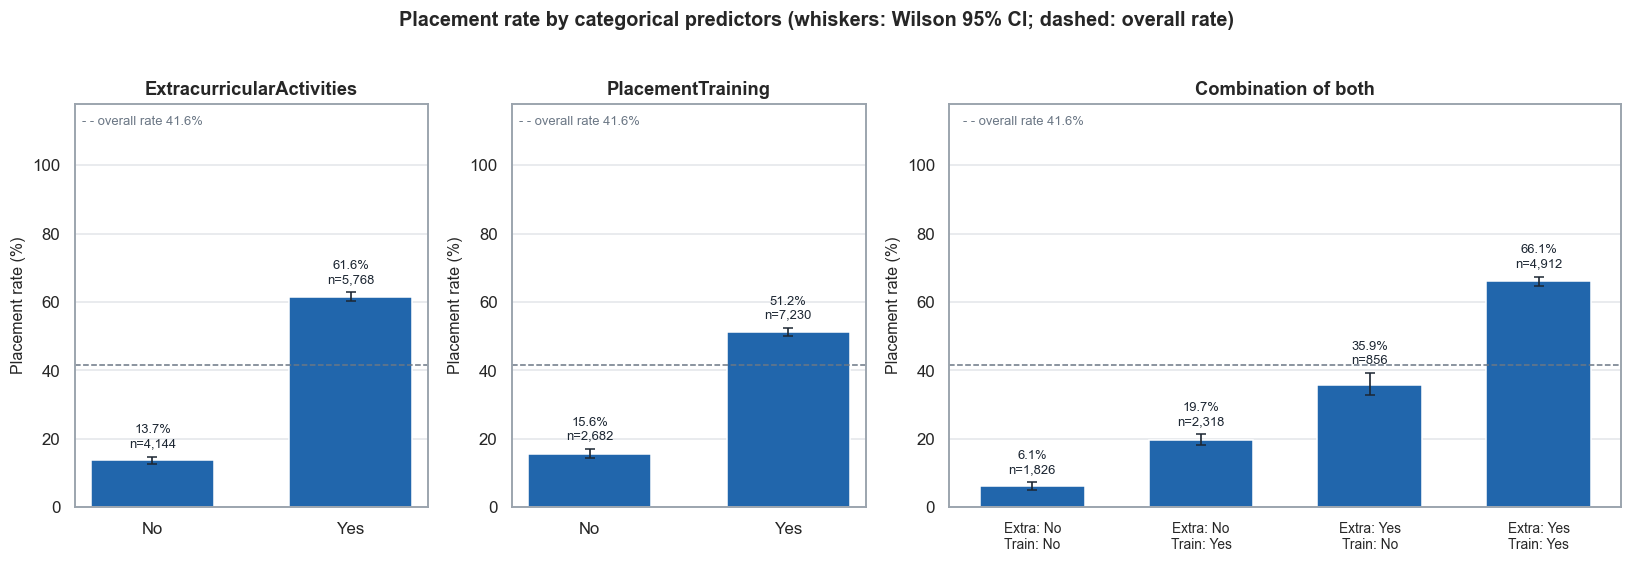

Association between the two binary predictors themselves:


PlacementTraining,No,Yes
ExtracurricularActivities,,
No,44.1,55.9
Yes,14.8,85.2


In [14]:
for c in CATB:
    t = rate_table(df[c])
    print(f"--- {c} ---"); print(t.assign(share_pct=t.n / len(df) * 100, rate=t.rate * 100, ci_lo=t.ci_lo * 100, ci_hi=t.ci_hi * 100).round(1).to_string(), "\n")
    for lvl, r in t.iterrows():
        add("categorical_rate", f"{c}={lvl}: placement_rate_%", round(r.rate * 100, 2), f"n={int(r.n)}")
combo = df["ExtracurricularActivities"].map({"Yes": "Extra: Yes", "No": "Extra: No"}) + " / " + df["PlacementTraining"].map({"Yes": "Train: Yes", "No": "Train: No"})
combo = pd.Categorical(combo, ["Extra: No / Train: No", "Extra: No / Train: Yes", "Extra: Yes / Train: No", "Extra: Yes / Train: Yes"])
fig, axes = plt.subplots(1, 3, figsize=(W, 5), gridspec_kw={"width_ratios": [1, 1, 1.9]})
rate_bar(axes[0], df["ExtracurricularActivities"], "ExtracurricularActivities", rot=0)
rate_bar(axes[1], df["PlacementTraining"], "PlacementTraining", rot=0)
tc = rate_bar(axes[2], pd.Series(combo, index=df.index), "Combination of both", rot=0)
axes[2].set_xticklabels([l.get_text().replace(" / ", "\n") for l in axes[2].get_xticklabels()], fontsize=9)
fig.suptitle("Placement rate by categorical predictors (whiskers: Wilson 95% CI; dashed: overall rate)", y=1.02, fontsize=13, fontweight="semibold")
save(fig, "eda_05_categorical_vs_placement")
for lvl, r in tc.iterrows(): add("categorical_rate", f"combo {lvl}: placement_rate_%", round(r.rate * 100, 2), f"n={int(r.n)}")
print("Association between the two binary predictors themselves:")
display(pd.crosstab(df["ExtracurricularActivities"], df["PlacementTraining"], normalize="index").mul(100).round(1))

## 6. Correlation analysis
Pearson correlations are computed first, with Spearman rank correlations alongside as a check.
**Correlation measures association, not causation**: a positive correlation between a feature and placement does not show that
the feature causes placement - both may reflect shared underlying factors (e.g. overall academic strength).
**Limitation of Pearson:** it measures *linear* association and assumes interval-scaled variables. Several predictors here
are discrete or ordinal (3-4 levels) and Phase 1 / section 4 showed non-monotonic relationships, so Pearson can understate or
misrepresent them (a U- or step-shaped relationship can have a near-zero *r*). The correlation with a 0/1 target is the
point-biserial correlation, which is simply Pearson on the encoded target.

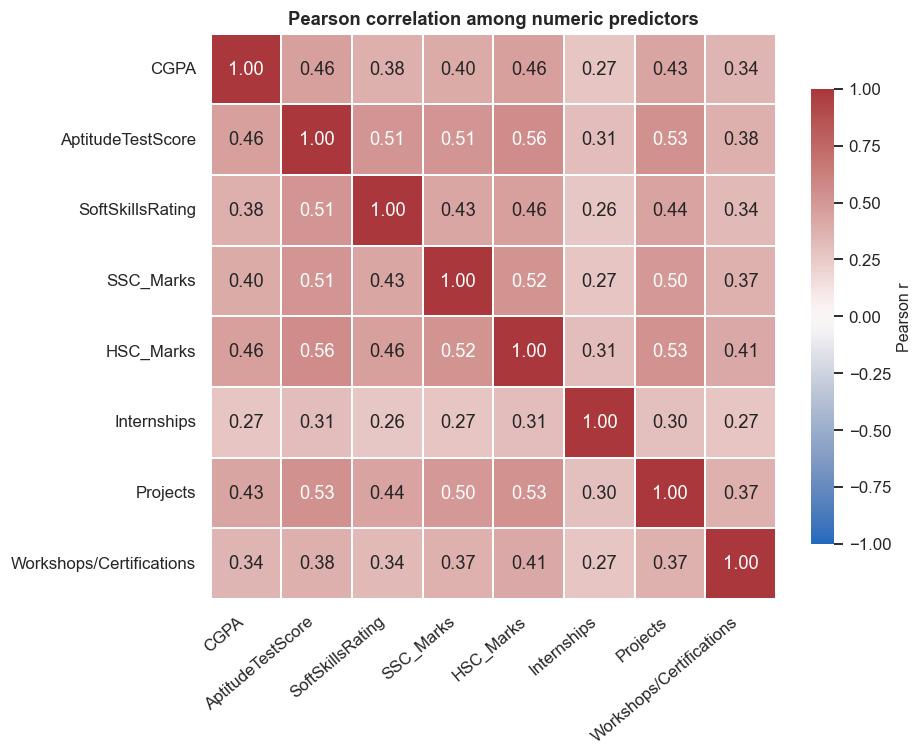

,pearson_r (point-biserial),spearman_rho
Internships,0.252,0.256
Workshops/Certifications,0.357,0.358
CGPA,0.419,0.443
SoftSkillsRating,0.422,0.444
SSC_Marks,0.466,0.461
Projects,0.471,0.474
HSC_Marks,0.501,0.486
AptitudeTestScore,0.517,0.530


In [15]:
corr = df[NUM].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8.6, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, linewidths=1, linecolor="white",
            cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation among numeric predictors"); ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "eda_06_correlation_matrix")
pr = df[NUM].corrwith(y, method="pearson"); sp = df[NUM].corrwith(y, method="spearman")
ct = pd.DataFrame({"pearson_r (point-biserial)": pr, "spearman_rho": sp}).sort_values("pearson_r (point-biserial)")
ct.round(3)

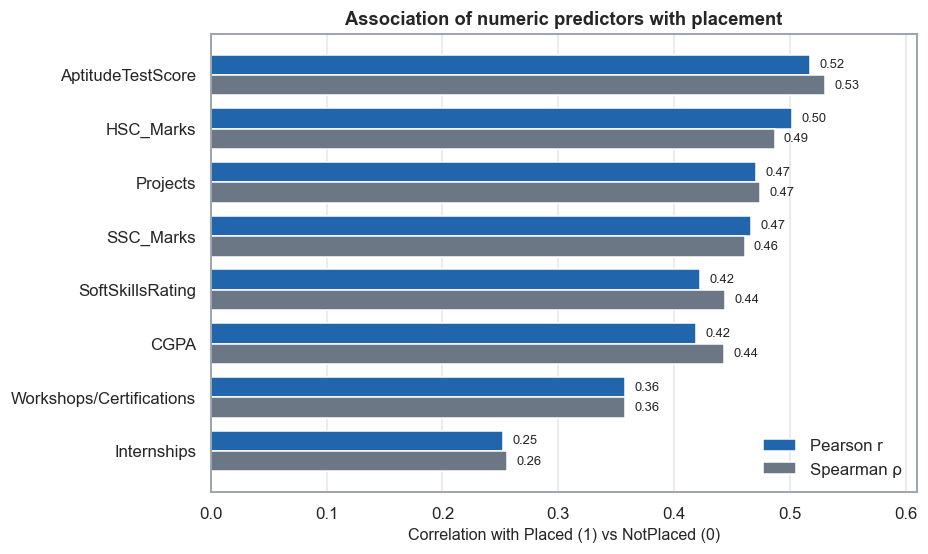

Strongest predictor-predictor correlations:
AptitudeTestScore  HSC_Marks           0.559
                   Projects            0.535
HSC_Marks          Projects            0.530
SSC_Marks          HSC_Marks           0.521
AptitudeTestScore  SoftSkillsRating    0.509
                   SSC_Marks           0.509


In [16]:
fig, ax = plt.subplots(figsize=(8.6, 5.2))
yy = np.arange(len(ct)); h = 0.38
ax.barh(yy + h / 2, ct.iloc[:, 0], height=h, color=PLACED_C, label="Pearson r")
ax.barh(yy - h / 2, ct.iloc[:, 1], height=h, color=NEUTRAL, label="Spearman ρ")
for i, (a, b) in enumerate(zip(ct.iloc[:, 0], ct.iloc[:, 1])):
    ax.text(a + 0.008, i + h / 2, f"{a:.2f}", va="center", fontsize=8.5); ax.text(b + 0.008, i - h / 2, f"{b:.2f}", va="center", fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(ct.index); ax.set_xlim(0, max(ct.max()) * 1.15); ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("Correlation with Placed (1) vs NotPlaced (0)"); ax.set_title("Association of numeric predictors with placement"); ax.grid(axis="y", visible=False)
save(fig, "eda_06b_correlation_with_target")
for c in NUM:
    add("correlation_with_target", f"{c}: pearson_r", round(pr[c], 3)); add("correlation_with_target", f"{c}: spearman_rho", round(sp[c], 3))
upper = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
print("Strongest predictor-predictor correlations:"); print(upper.head(6).round(3).to_string())
add("correlation_predictors", "max_abs_pairwise_pearson", round(upper.abs().max(), 3), upper.abs().idxmax().__str__())

## 7. Multivariate views
A few targeted plots rather than a full pair-plot. Scores are recorded in coarse steps, so points overlap heavily; a small
jitter (display only) and transparency are used, and a binned placement-rate map (exploratory bins) shows the joint pattern
more reliably than raw dots.

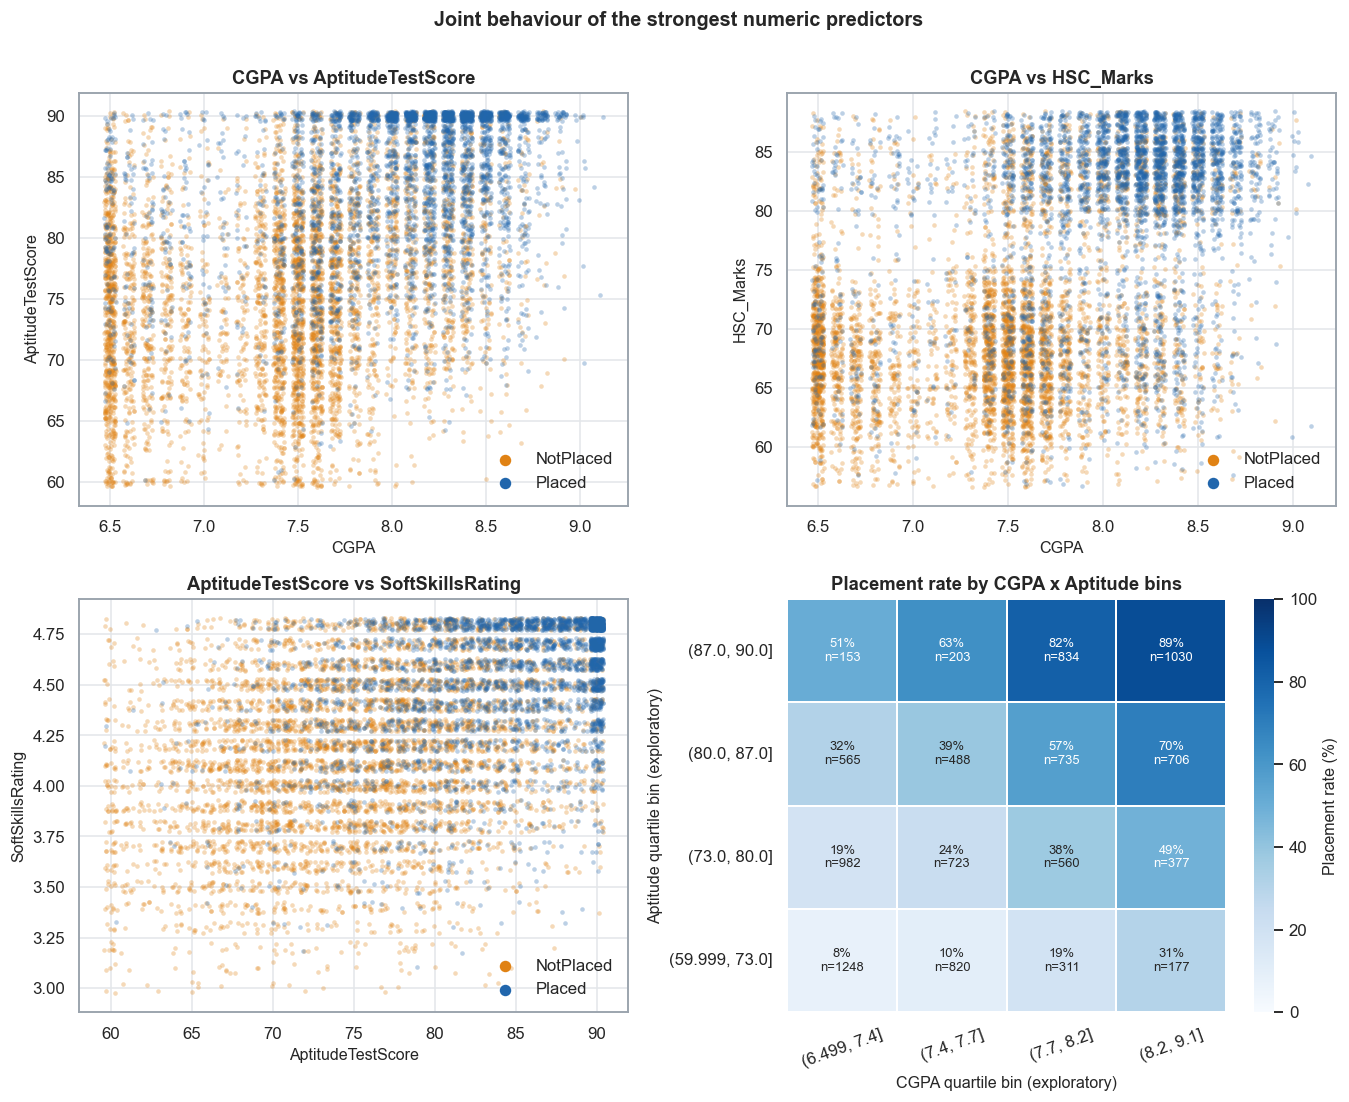

Binned rates (%):


,"(6.499, 7.4]","(7.4, 7.7]","(7.7, 8.2]","(8.2, 9.1]"
"(59.999, 73.0]",7.8,10.0,19.0,30.5
"(73.0, 80.0]",18.6,23.7,37.7,48.5
"(80.0, 87.0]",31.5,38.9,56.7,70.0
"(87.0, 90.0]",51.0,63.1,81.5,88.7


In [17]:
rng = np.random.default_rng(42)
def jit(s, scale): return s + rng.uniform(-scale, scale, len(s))
pairs = [("CGPA", "AptitudeTestScore", 0.03, 0.4), ("CGPA", "HSC_Marks", 0.03, 0.4), ("AptitudeTestScore", "SoftSkillsRating", 0.4, 0.03)]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 10))
for ax, (xc, yc, jx, jy) in zip(axes.ravel(), pairs):
    for g in ORDER:
        m = df[TARGET] == g
        ax.scatter(jit(df.loc[m, xc], jx), jit(df.loc[m, yc], jy), s=9, alpha=0.30, color=PAL[g], label=g, linewidths=0)
    ax.set_xlabel(xc); ax.set_ylabel(yc); ax.set_title(f"{xc} vs {yc}")
    leg = ax.legend(frameon=False, markerscale=2.5, loc="lower right"); [h.set_alpha(1) for h in leg.legend_handles]
# exploratory binned rate map (temporary bins)
cg = pd.qcut(df["CGPA"], 4, duplicates="drop"); ap = pd.qcut(df["AptitudeTestScore"], 4, duplicates="drop")
r = y.groupby([ap, cg], observed=True).mean().unstack(); n = y.groupby([ap, cg], observed=True).size().unstack()
ann = (r * 100).round(0).astype(int).astype(str) + "%\nn=" + n.astype(str)
r.index = [str(i) for i in r.index]; r.columns = [str(i) for i in r.columns]; ann.index, ann.columns = r.index, r.columns
sns.heatmap(r * 100, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=100, linewidths=1, linecolor="white", annot_kws={"fontsize": 8.5},
            cbar_kws={"label": "Placement rate (%)"}, ax=axes[1, 1])
axes[1, 1].invert_yaxis(); axes[1, 1].set_xlabel("CGPA quartile bin (exploratory)"); axes[1, 1].set_ylabel("Aptitude quartile bin (exploratory)")
axes[1, 1].set_title("Placement rate by CGPA x Aptitude bins"); axes[1, 1].tick_params(axis="x", rotation=20); axes[1, 1].tick_params(axis="y", rotation=0)
fig.suptitle("Joint behaviour of the strongest numeric predictors", y=1.0, fontsize=13, fontweight="semibold")
save(fig, "eda_07_multivariate")
print("Binned rates (%):"); display((r * 100).round(1))
add("multivariate", "rate_lowest_cgpa_x_lowest_aptitude_%", round(r.iloc[0, 0] * 100, 1)); add("multivariate", "rate_highest_cgpa_x_highest_aptitude_%", round(r.iloc[-1, -1] * 100, 1))

## 8. Placement-rate ranking
**Exploratory bins notice:** the quantile bins used below exist only for these charts. They are held in temporary variables,
are not saved, and are **not** model features; the dataframe columns are asserted unchanged at the end of the notebook.

,variable,level,n,placed,rate,ci_lo,ci_hi
rank,,,,,,,
1,Workshops/Certifications,2,3219,2337,72.6,71.0,74.1
2,Projects,3,3787,2703,71.4,69.9,72.8
3,Internships,2,2394,1651,69.0,67.1,70.8
4,ExtracurricularActivities,Yes,5768,3552,61.6,60.3,62.8
5,Projects,0,30,18,60.0,42.3,75.4
6,Workshops/Certifications,3,284,160,56.3,50.5,62.0
7,PlacementTraining,Yes,7230,3701,51.2,50.0,52.3
8,Internships,0,1983,663,33.4,31.4,35.5
9,Internships,1,5535,1805,32.6,31.4,33.9


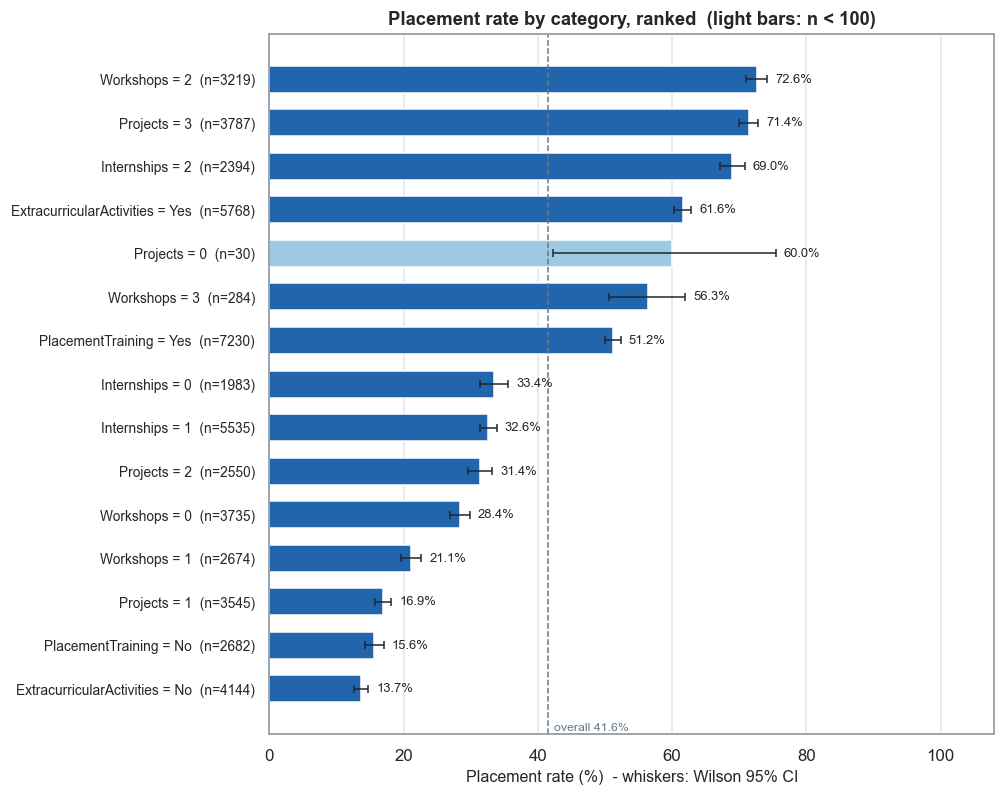

In [18]:
parts = []
for c in ["Internships", "Projects", "Workshops/Certifications", "ExtracurricularActivities", "PlacementTraining"]:
    t = rate_table(df[c]).reset_index().rename(columns={c: "level"}); t.insert(0, "variable", c); t["level"] = t["level"].astype(str); parts.append(t)
rank = pd.concat(parts).sort_values("rate", ascending=False).reset_index(drop=True)
rank["label"] = rank.variable.str.replace("Workshops/Certifications", "Workshops") + " = " + rank.level + "  (n=" + rank.n.astype(str) + ")"
tbl = rank[["variable", "level", "n", "placed", "rate", "ci_lo", "ci_hi"]].copy()
for c in ["rate", "ci_lo", "ci_hi"]: tbl[c] = (tbl[c] * 100).round(1)
tbl.index = tbl.index + 1; tbl.index.name = "rank"
display(tbl)
fig, ax = plt.subplots(figsize=(W * 0.62, 7.4))
yy = np.arange(len(rank))[::-1]
ax.barh(yy, rank.rate * 100, color=np.where(rank.n < 100, "#9ecae1", PLACED_C), height=0.62)
ax.errorbar(rank.rate * 100, yy, xerr=[(rank.rate - rank.ci_lo) * 100, (rank.ci_hi - rank.rate) * 100], fmt="none", ecolor="#1d2733", lw=1, capsize=2.5)
for yi, r_, hi in zip(yy, rank.rate, rank.ci_hi): ax.text(hi * 100 + 1.2, yi, f"{r_*100:.1f}%", va="center", fontsize=8.5)
ax.axvline(OVERALL * 100, color=NEUTRAL, ls="--", lw=1); ax.text(OVERALL * 100 + 0.8, -0.95, f"overall {OVERALL*100:.1f}%", fontsize=8, color=NEUTRAL)
ax.set_yticks(yy); ax.set_yticklabels(rank.label, fontsize=9); ax.set_xlim(0, 108); ax.set_xlabel("Placement rate (%)  - whiskers: Wilson 95% CI")
ax.set_title("Placement rate by category, ranked  (light bars: n < 100)"); ax.grid(axis="y", visible=False)
save(fig, "eda_08_rate_ranking")

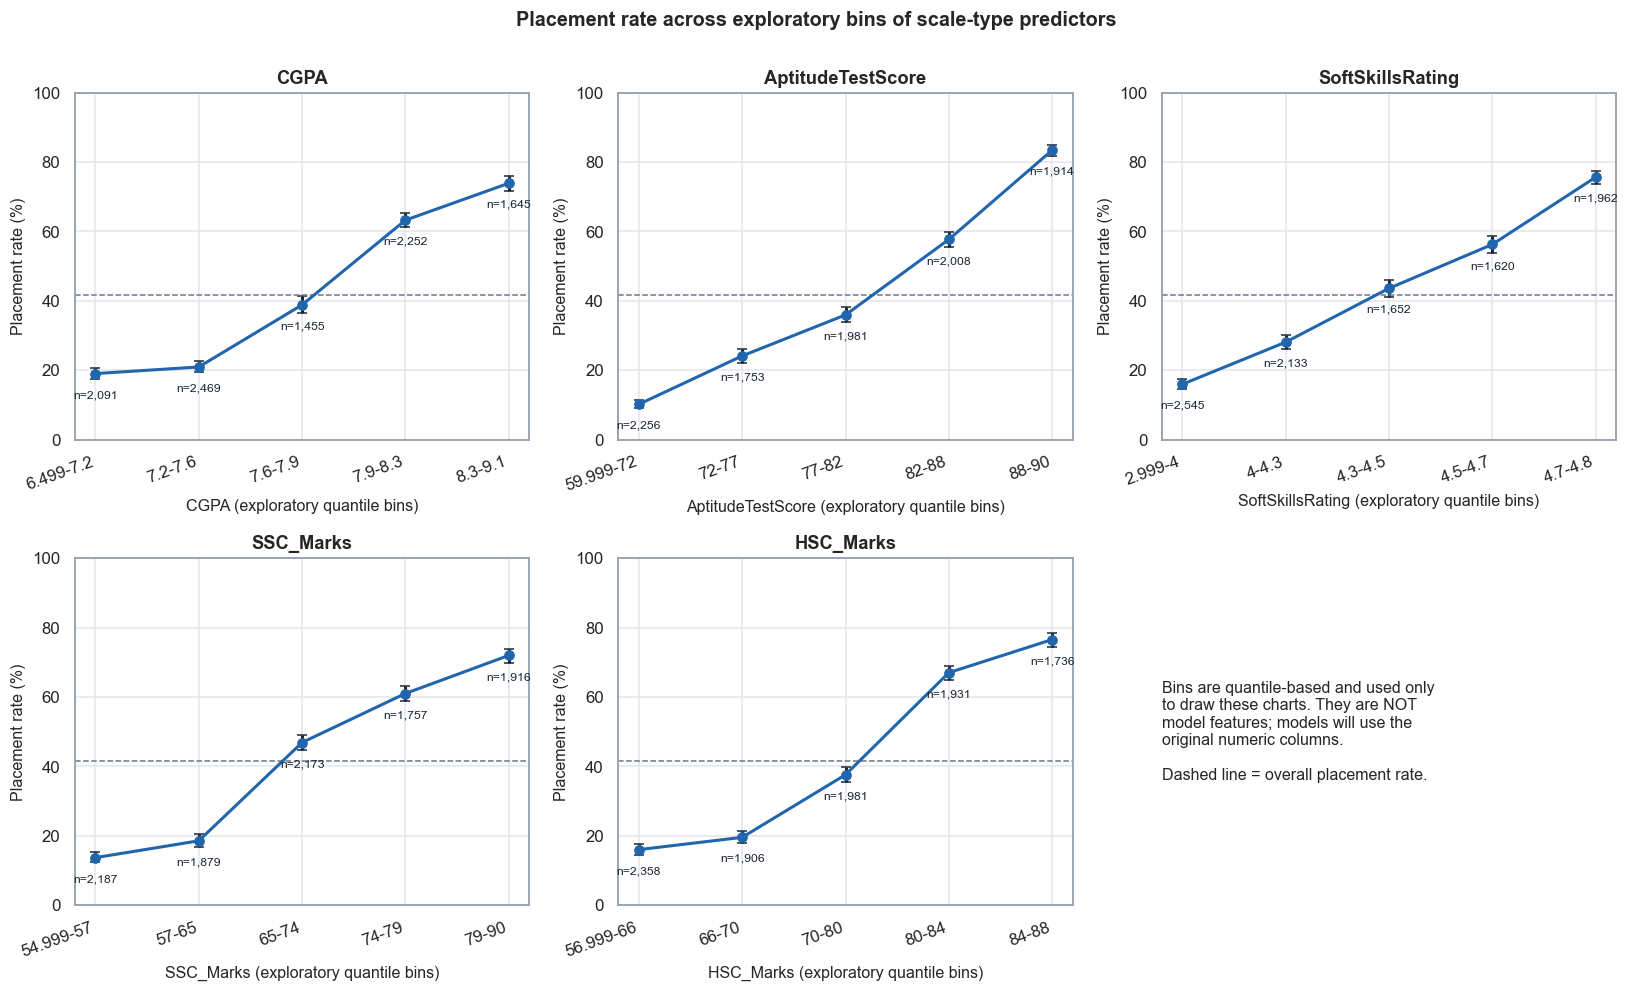

In [19]:
# Exploratory quantile bins for continuous-scale variables (VISUALISATION ONLY - never added to df)
fig, axes = plt.subplots(2, 3, figsize=(W, 9))
for ax, c in zip(axes.ravel(), CONT):
    b = pd.qcut(df[c], 5, duplicates="drop")
    t = rate_table(b); lab = [f"{i.left:g}-{i.right:g}" for i in t.index]; x = np.arange(len(t))
    ax.errorbar(x, t.rate * 100, yerr=[(t.rate - t.ci_lo) * 100, (t.ci_hi - t.rate) * 100], fmt="o-", color=PLACED_C, ecolor="#1d2733", capsize=3, lw=2, ms=6)
    for xi, (r_, n_) in enumerate(zip(t.rate, t.n)): ax.text(xi, r_ * 100 - 7, f"n={n_:,}", ha="center", fontsize=8, color="#1d2733")
    ax.axhline(OVERALL * 100, color=NEUTRAL, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(lab, rotation=20, ha="right"); ax.set_ylim(0, 100)
    ax.set_xlabel(f"{c} (exploratory quantile bins)"); ax.set_ylabel("Placement rate (%)"); ax.set_title(c)
    for i, r_ in enumerate(t.rate): add("binned_rate_exploratory", f"{c} bin {lab[i]}: rate_%", round(r_ * 100, 1), f"n={int(t.n.iloc[i])}")
ax = axes.ravel()[-1]; ax.axis("off")
ax.text(0, 0.5, "Bins are quantile-based and used only\nto draw these charts. They are NOT\nmodel features; models will use the\noriginal numeric columns.\n\nDashed line = overall placement rate.", fontsize=10.5, va="center")
fig.suptitle("Placement rate across exploratory bins of scale-type predictors", y=1.0, fontsize=13, fontweight="semibold")
save(fig, "eda_08b_binned_rates")

## 9. Train / validation / test sanity check
Purpose: confirm the stratified split is representative. Differences of a few percent between splits of this size are expected
from sampling alone; the KS statistic (max gap between empirical CDFs) and percentage-point gaps quantify any shift.

In [20]:
chk = ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "Internships", "Projects"]
names = ["train", "validation", "test"]
rows = []
for s, d in splits.items():
    r_ = {"split": s, "n": len(d), "Placed_%": (d[TARGET] == "Placed").mean() * 100}
    for c in chk: r_[f"{c} mean"] = d[c].mean(); r_[f"{c} sd"] = d[c].std()
    rows.append(r_)
st = pd.DataFrame(rows).set_index("split"); display(st.round(3))
for s in names:
    add("split_check", f"{s}: n", len(splits[s])); add("split_check", f"{s}: placed_%", round(st.loc[s, "Placed_%"], 2))
    for c in chk: add("split_check", f"{s}: {c} mean", round(st.loc[s, f"{c} mean"], 3))

res = []
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    for c in ["CGPA", "AptitudeTestScore", "SoftSkillsRating"]:
        k = stats.ks_2samp(splits[a][c], splits[b][c]); res.append((f"{a} vs {b}", c, "KS statistic", k.statistic, k.pvalue))
    for c in ["Internships", "Projects", TARGET]:
        pa = splits[a][c].value_counts(normalize=True); pb = splits[b][c].value_counts(normalize=True)
        gap = (pa.sub(pb, fill_value=0).abs().max()) * 100
        ct_ = pd.concat([splits[a][c].value_counts(), splits[b][c].value_counts()], axis=1).fillna(0)
        res.append((f"{a} vs {b}", c, "max |pp gap|", gap, stats.chi2_contingency(ct_)[1]))
shift = pd.DataFrame(res, columns=["pair", "variable", "measure", "value", "p_value"])
shift_wide = shift.pivot(index=["variable", "measure"], columns="pair", values="value").round(3)
display(shift_wide)
print("max KS statistic:", round(shift[shift.measure == "KS statistic"].value.max(), 3), "| max percentage-point gap:", round(shift[shift.measure == "max |pp gap|"].value.max(), 2))
print("Smallest p-value across the 18 comparisons:", round(shift.p_value.min(), 3), "(with 18 looks, one or two p < .05 would arise by chance alone)")
add("split_check", "max_KS_statistic", round(shift[shift.measure == "KS statistic"].value.max(), 4))
add("split_check", "max_pct_point_gap_discrete", round(shift[shift.measure == "max |pp gap|"].value.max(), 3))
add("split_check", "min_p_value_of_18", round(shift.p_value.min(), 4))

,n,Placed_%,CGPA mean,CGPA sd,AptitudeTestScore mean,AptitudeTestScore sd,SoftSkillsRating mean,SoftSkillsRating sd,Internships mean,Internships sd,Projects mean,Projects sd
split,,,,,,,,,,,,
train,6938,41.554,7.699,0.638,79.323,8.164,4.321,0.413,1.046,0.662,2.024,0.867
validation,1487,41.560,7.688,0.645,79.313,8.145,4.316,0.411,1.029,0.663,2.001,0.867
test,1487,41.560,7.667,0.644,79.572,7.997,4.320,0.400,1.034,0.671,2.007,0.869


,pair,train vs test,train vs validation,validation vs test
variable,measure,,,
AptitudeTestScore,KS statistic,0.019,0.013,0.028
CGPA,KS statistic,0.038,0.016,0.028
Internships,max |pp gap|,1.144,0.875,1.009
PlacementStatus,max |pp gap|,0.006,0.006,0.000
Projects,max |pp gap|,1.002,1.309,1.143
SoftSkillsRating,KS statistic,0.021,0.012,0.021


max KS statistic: 0.038 | max percentage-point gap: 1.31
Smallest p-value across the 18 comparisons: 0.057 (with 18 looks, one or two p < .05 would arise by chance alone)


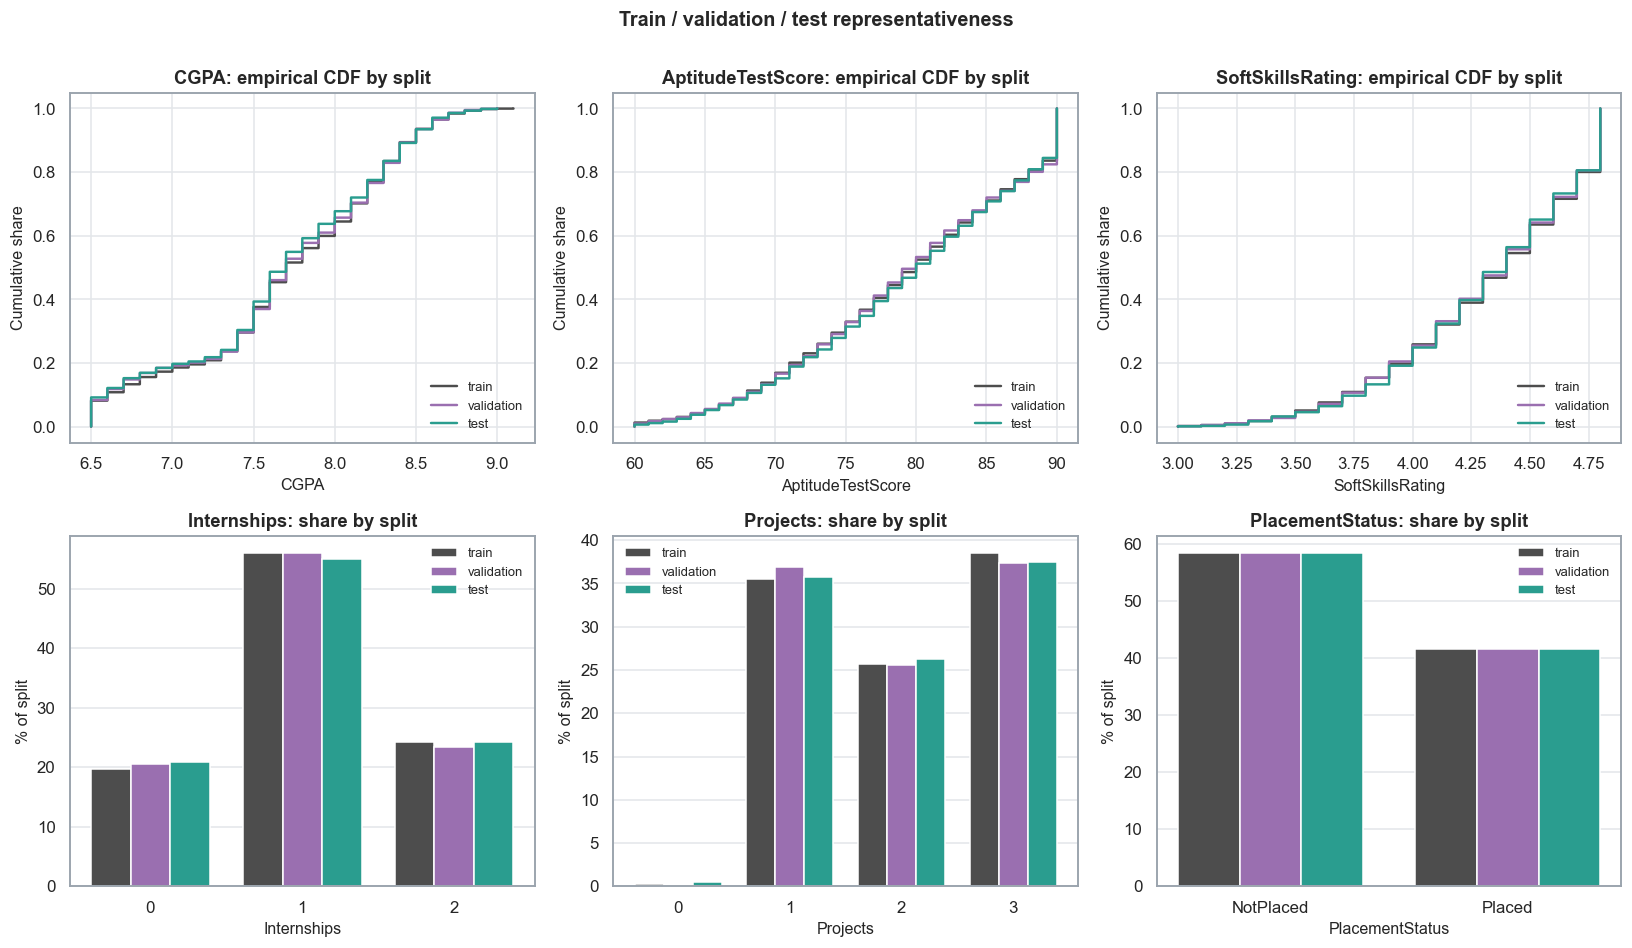

In [21]:
SPC = {"train": "#4d4d4d", "validation": "#9a6fb0", "test": "#2a9d8f"}
fig, axes = plt.subplots(2, 3, figsize=(W, 8.6))
for ax, c in zip(axes[0], ["CGPA", "AptitudeTestScore", "SoftSkillsRating"]):
    for s in names:
        v = np.sort(splits[s][c].values); ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=SPC[s], lw=1.6, label=s)
    ax.set_xlabel(c); ax.set_ylabel("Cumulative share"); ax.set_title(f"{c}: empirical CDF by split"); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
def grouped(ax, series_fn, title, xlabel):
    levels = sorted(series_fn(splits["train"]).unique()); w = 0.26
    for k, s in enumerate(names):
        p = series_fn(splits[s]).value_counts(normalize=True).reindex(levels).fillna(0) * 100
        ax.bar(np.arange(len(levels)) + (k - 1) * w, p.values, width=w, color=SPC[s], label=s)
    ax.set_xticks(np.arange(len(levels))); ax.set_xticklabels(levels); ax.set_xlabel(xlabel); ax.set_ylabel("% of split"); ax.set_title(title)
    ax.legend(frameon=False, fontsize=8.5); ax.grid(axis="x", visible=False)
grouped(axes[1, 0], lambda d: d["Internships"], "Internships: share by split", "Internships")
grouped(axes[1, 1], lambda d: d["Projects"], "Projects: share by split", "Projects")
grouped(axes[1, 2], lambda d: d[TARGET], "PlacementStatus: share by split", "PlacementStatus")
fig.suptitle("Train / validation / test representativeness", y=1.0, fontsize=13, fontweight="semibold")
save(fig, "eda_09_split_sanity")

## 10. Preparation for formal statistical testing (Phase 3)
No inferential tests are run here. The table lists the relationships that look worth testing, the candidate test, and why that
test suits the variable types. Observed numbers are filled in from the analysis above.

In [22]:
T = {k: rate_table(df[k]) for k in ["Internships", "Projects", "Workshops/Certifications", "ExtracurricularActivities", "PlacementTraining"]}
pct = lambda t, lvl: f"{t.loc[lvl, 'rate']*100:.1f}%"
d_ = cmp.cohens_d
plan = pd.DataFrame([
 ("CGPA, AptitudeTestScore, SoftSkillsRating, SSC_Marks, HSC_Marks vs placement",
  f"Placed students score higher on all five; Cohen's d from {d_[CONT].min():.2f} ({d_[CONT].idxmin()}) to {d_[CONT].max():.2f} ({d_[CONT].idxmax()})",
  "Mann-Whitney U (primary) + Welch t-test (sensitivity); effect size: Cohen's d and rank-biserial / AUC",
  "Scores are bounded, mildly skewed and recorded in coarse steps with many ties, so a rank-based test avoids normality assumptions; Welch handles unequal variances. With n~10k, p-values will be tiny, so effect size is what matters."),
 ("ExtracurricularActivities vs placement",
  f"Placement rate {pct(T['ExtracurricularActivities'],'Yes')} (Yes) vs {pct(T['ExtracurricularActivities'],'No')} (No)",
  "Chi-square test of independence (2x2); effect size: odds ratio with CI and phi",
  "Two binary variables; expected cell counts are large, so the chi-square approximation is valid. Odds ratio gives an interpretable effect size."),
 ("PlacementTraining vs placement",
  f"Placement rate {pct(T['PlacementTraining'],'Yes')} (Yes) vs {pct(T['PlacementTraining'],'No')} (No)",
  "Chi-square test of independence (2x2); odds ratio with CI",
  "Same reasoning as above. Also check its overlap with ExtracurricularActivities (the two co-vary)."),
 ("Internships vs placement (non-monotonic)",
  f"Rates {pct(T['Internships'],0)} / {pct(T['Internships'],1)} / {pct(T['Internships'],2)} for 0 / 1 / 2: flat between 0 and 1, jump at 2",
  "Chi-square (3x2) for overall association; two-proportion z-test for 0 vs 1; do NOT rely on a linear trend test (Cochran-Armitage)",
  "A trend test presumes ordered, monotonic change, which the data do not show. The 0-vs-1 contrast directly tests the flat segment."),
 ("Projects vs placement (non-monotonic, sparse level 0)",
  f"Rates {pct(T['Projects'],0)} / {pct(T['Projects'],1)} / {pct(T['Projects'],2)} / {pct(T['Projects'],3)} for 0-3; level 0 has only n={int(T['Projects'].loc[0,'n'])}",
  "Chi-square on levels 1-3; Fisher's exact (or exact CI) for the Projects = 0 group",
  "Level 0 is too small for chi-square validity (expected counts) and its rate is highly uncertain; exact methods are appropriate."),
 ("Workshops/Certifications vs placement (non-monotonic)",
  f"Rates {pct(T['Workshops/Certifications'],0)} / {pct(T['Workshops/Certifications'],1)} / {pct(T['Workshops/Certifications'],2)} / {pct(T['Workshops/Certifications'],3)} for 0-3; level 1 below level 0",
  "Chi-square (4x2) overall; pairwise two-proportion tests with multiple-comparison correction (Holm)",
  "Pairwise comparisons identify where the pattern departs from monotonic; correction is needed since several pairs are compared."),
 ("Is the Workshops/Projects pattern confounded by overall profile strength?",
  "Higher-workshop groups also have higher CGPA/aptitude and more extracurricular/training; patterns can differ within aptitude bands",
  "Cochran-Mantel-Haenszel test stratified by aptitude band; later a multivariable logistic regression (inference form)",
  "Stratified testing asks whether the association persists after holding another variable roughly fixed; a necessary check before interpreting a raw rate."),
 ("Multicollinearity among scores",
  f"Strongest predictor-predictor Pearson r = {upper.abs().max():.2f} ({upper.abs().idxmax()[0]} / {upper.abs().idxmax()[1]})",
  "Spearman correlations and variance inflation factors",
  "Rank correlation is robust for bounded, discrete scores; VIF quantifies redundancy relevant to linear models."),
], columns=["Feature / relationship", "Observed pattern", "Candidate statistical test", "Reason"])
pd.set_option("display.max_colwidth", 200)
plan.to_csv(MET / "03_phase3_test_plan.csv", index=False)
plan

,Feature / relationship,Observed pattern,Candidate statistical test,Reason
0,"CGPA, AptitudeTestScore, SoftSkillsRating, SSC_Marks, HSC_Marks vs placement",Placed students score higher on all five; Cohen's d from 0.94 (CGPA) to 1.23 (AptitudeTestScore),Mann-Whitney U (primary) + Welch t-test (sensitivity); effect size: Cohen's d and rank-biserial / AUC,"Scores are bounded, mildly skewed and recorded in coarse steps with many ties, so a rank-based test avoids normality assumptions; Welch handles unequal variances. With n~10k, p-values will be tiny..."
1,ExtracurricularActivities vs placement,Placement rate 61.6% (Yes) vs 13.7% (No),Chi-square test of independence (2x2); effect size: odds ratio with CI and phi,"Two binary variables; expected cell counts are large, so the chi-square approximation is valid. Odds ratio gives an interpretable effect size."
2,PlacementTraining vs placement,Placement rate 51.2% (Yes) vs 15.6% (No),Chi-square test of independence (2x2); odds ratio with CI,Same reasoning as above. Also check its overlap with ExtracurricularActivities (the two co-vary).
3,Internships vs placement (non-monotonic),"Rates 33.4% / 32.6% / 69.0% for 0 / 1 / 2: flat between 0 and 1, jump at 2",Chi-square (3x2) for overall association; two-proportion z-test for 0 vs 1; do NOT rely on a linear trend test (Cochran-Armitage),"A trend test presumes ordered, monotonic change, which the data do not show. The 0-vs-1 contrast directly tests the flat segment."
4,"Projects vs placement (non-monotonic, sparse level 0)",Rates 60.0% / 16.9% / 31.4% / 71.4% for 0-3; level 0 has only n=30,Chi-square on levels 1-3; Fisher's exact (or exact CI) for the Projects = 0 group,Level 0 is too small for chi-square validity (expected counts) and its rate is highly uncertain; exact methods are appropriate.
5,Workshops/Certifications vs placement (non-monotonic),Rates 28.4% / 21.1% / 72.6% / 56.3% for 0-3; level 1 below level 0,Chi-square (4x2) overall; pairwise two-proportion tests with multiple-comparison correction (Holm),Pairwise comparisons identify where the pattern departs from monotonic; correction is needed since several pairs are compared.
6,Is the Workshops/Projects pattern confounded by overall profile strength?,Higher-workshop groups also have higher CGPA/aptitude and more extracurricular/training; patterns can differ within aptitude bands,Cochran-Mantel-Haenszel test stratified by aptitude band; later a multivariable logistic regression (inference form),Stratified testing asks whether the association persists after holding another variable roughly fixed; a necessary check before interpreting a raw rate.
7,Multicollinearity among scores,Strongest predictor-predictor Pearson r = 0.56 (AptitudeTestScore / HSC_Marks),Spearman correlations and variance inflation factors,"Rank correlation is robust for bounded, discrete scores; VIF quantifies redundancy relevant to linear models."


## 11. EDA findings

﻿> All statements describe **association in this dataset** (n = 9,912 distinct feature profiles). None is a causal claim.

### A. Strong observed patterns
- **Every predictor is associated with placement, and most strongly the scores.** Standardised mean differences (Placed minus NotPlaced): AptitudeTestScore d = 1.23, HSC_Marks 1.18, Projects 1.08, SSC_Marks 1.07, SoftSkillsRating 0.95, CGPA 0.94. Correlations with the 0/1 target range from r = 0.52 (aptitude) and 0.50 (HSC) down to 0.42 (CGPA, soft skills).
- **Students who report extracurricular activities show a much higher observed placement rate** (61.6% vs 13.7%), as do students with placement training (51.2% vs 15.6%).
- **The two binary predictors co-occur and their effects combine:** observed placement rates run from 6.1% (neither, n = 1,826) through 19.7% (training only) and 35.9% (extracurricular only) to 66.1% (both, n = 4,912).
- **The joint pattern across academic scores is steep:** in the exploratory CGPA x aptitude grid the observed rate rises from 7.8% (lowest bins) to 88.7% (highest bins).

### B. Weaker / moderate patterns
- Internships (d = 0.53, r = 0.25) and Workshops/Certifications (d = 0.78, r = 0.36) have the smallest correlations with placement; the Internships association is carried almost entirely by the jump at 2 (see C).
- CGPA and SoftSkillsRating have large mean differences (d about 0.94) but only moderate linear correlation (r about 0.42), consistent with overlapping distributions.
- Pearson and Spearman agree closely for all eight numeric predictors (differences <= 0.03), so rank-based and linear summaries tell the same story for these variables.

### C. Unexpected / non-monotonic patterns
- **Internships:** 33.4% (0) vs 32.6% (1) vs 69.0% (2). No visible gain from 0 to 1, then a large jump at 2.
- **Workshops/Certifications:** 28.4% (0), 21.1% (1), 72.6% (2), 56.3% (3). Level 1 sits *below* level 0 and level 3 *below* level 2.
- **Projects:** 60.0% (0, n = 30 only), 16.9% (1), 31.4% (2), 71.4% (3). The Projects = 0 rate rests on 30 students (Wilson 95% CI 42-75%) and should not be over-read.
- **Composition:** students with 2 workshops have higher average CGPA (8.05 vs 7.5), aptitude (84.8 vs 76-77), more projects (2.56 vs 1.7) and far more extracurriculars (87% vs 41-43%). Their raw placement rate partly reflects who sits at that level.
- **Within aptitude terciles, the dip at Workshops = 1 persists** (low 15.4% -> 9.9%, mid 29.3% -> 25.3%, high 58.4% -> 53.3%), as does the 2 -> 3 drop in the mid and high bands (low band n = 55 at level 3). So the non-monotonicity is not explained by aptitude alone; other covariates (e.g. extracurriculars) may contribute. This remains descriptive.

### D. Potential data-quality / data-character concerns
- Hard floors and ceilings with pile-ups at the limits (CGPA at 6.5, aptitude at 90, soft skills at 4.8, SSC at 55) in the violins; ranges have no tails.
- Very large, systematic effects across *all* predictors plus step-like non-monotonic count patterns are consistent with a rule-based or synthetically generated dataset. This is an observation, not a conclusion; the dataset card does not state provenance. It also means model performance here may not transfer to real placement data.
- Predictors are moderately inter-correlated (max pairwise r = 0.56, aptitude / HSC), and ExtracurricularActivities and PlacementTraining co-occur (85% of extracurricular students also had training).
- 8 conflicting-label profiles (16 rows) were excluded in notebook 02. Within each pair every predictor is identical yet one student is Placed and one NotPlaced, and all 8 sit at the top of the range (aptitude 90, 2 workshops, 3 projects, extracurricular and training both Yes). The label therefore depends on something not captured by the features, or contains noise, at least in this high-profile region; this limits the best achievable accuracy there.

### E. Questions to test statistically in Phase 3
1. Does each numeric predictor differ between Placed and NotPlaced (Mann-Whitney U, effect sizes with CIs)?
2. Are ExtracurricularActivities and PlacementTraining associated with placement (chi-square, odds ratios), and are they associated with each other?
3. Is the Internships 0 vs 1 difference distinguishable from zero, and is the jump at 2 real?
4. Is the Workshops 1 < 0 and 3 < 2 pattern statistically distinguishable from noise, with multiple-comparison correction?
5. Does the Workshops/Projects association persist after stratifying on aptitude (Cochran-Mantel-Haenszel)?
6. How much redundancy exists among the score variables (VIF)?

### F. Features that may be useful for prediction
- All 10 predictors show a clear association with the outcome, so none is a candidate for removal at this stage; AptitudeTestScore, HSC_Marks, Projects, SSC_Marks and the two binary variables show the largest raw separations.
- Because Internships, Projects and Workshops/Certifications behave non-monotonically, a linear-in-count treatment may be inadequate; Phase 4 should compare treating them as numeric vs categorical, and tree-based models can capture steps natively.
- Possible interactions to examine later (not engineered here): Extracurricular x PlacementTraining, Projects x Workshops.
- No transformation, binning or feature creation was applied; exploratory bins were visualisation-only.

## 12. Save the numeric summary and final checks

In [23]:
summary = pd.DataFrame(SUMMARY)
summary.to_csv(MET / "03_eda_summary.csv", index=False)
print("Saved", MET / "03_eda_summary.csv", summary.shape)
# no engineered/binned feature leaked into the data; no model was trained
assert list(df.columns) == list(pd.read_csv(PROC / "modeling_dataset.csv").columns) and df.shape == (9912, 11)
assert not any(k in globals() for k in ("model", "clf", "LogisticRegression"))
print("Figures written:", len(list(FIGDIR.glob('*.png'))), "->", FIGDIR)
summary.head(15)

Saved D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\03_eda_summary.csv (128, 4)
Figures written: 13 -> D:\Student-Placement-Prediction\student-placement-prediction\results\figures\eda


,section,item,value,note
0,overview,rows,9912.000,
1,overview,predictors,10.000,
2,overview,placed_pct,41.560,
3,overview,notplaced_pct,58.440,
4,target,imbalance_ratio_notplaced_to_placed,1.406,
5,numeric_vs_target,CGPA: cohens_d,0.936,"Placed minus NotPlaced, pooled SD"
6,numeric_vs_target,CGPA: mean_placed,8.011,
7,numeric_vs_target,CGPA: mean_notplaced,7.467,
8,numeric_vs_target,AptitudeTestScore: cohens_d,1.227,"Placed minus NotPlaced, pooled SD"
9,numeric_vs_target,AptitudeTestScore: mean_placed,84.351,
